In [23]:
!uv sync

Resolved 112 packages in 5ms
Checked 108 packages in 12ms


## Librerías

In [24]:
import cv2 as cv
import numpy as np
import os
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Rutas

In [25]:
root = os.getcwd()

face_example = os.path.join(root, "faces/Approved/blue.png")
face_dir = os.path.join(root, "faces/Approved")

processed_dir = os.path.join(root, "Procesados")
os.makedirs(processed_dir, exist_ok=True)

gray_processed = os.path.join(processed_dir, "gray")
os.makedirs(gray_processed, exist_ok=True)

hsv_processed = os.path.join(processed_dir, "hsv")
os.makedirs(hsv_processed, exist_ok=True)

## Funciones

In [26]:
def plot_single_image(images: list, titles: list[str], isgray: list[bool]):
    """
    Plot a list of images with the titles inside a list of strings
    """
    for i in range(len(images)):
        plt.subplot(2, 3, i+1)
        if isgray[i] == True:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(images[i])
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()

def plot_multiple_images(images: dict[list], titles: dict[list], isgray: list):
    pass

def process_Otsu_image(image, img_path: str):
    img = cv.imread(img_path)

    imgGray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    ret,imgOtsu = cv.threshold(imgGray,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

    return ret, imgOtsu

def process_HSV_image(image, img_path: str):
    img = cv.imread(img_path)

    imgHSV = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    imgRecortada = imgHSV[:, :, 2]

    ret,imgOtsu = cv.threshold(imgRecortada,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

    return ret, imgOtsu

## Blanco y negro

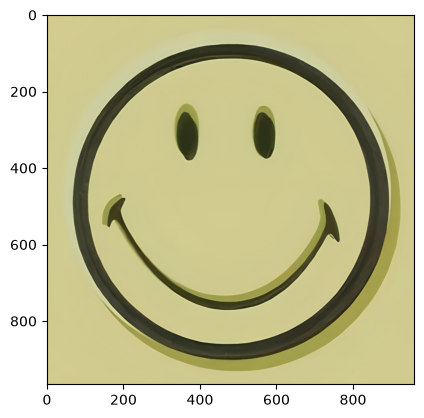

In [27]:
img = cv.imread(face_example)

plt.imshow(img)
plt.show()

Al mostrar las imágenes con matplotlib los grafica como RGB cuando `opencv` lo lee como BGR. Vamos a sacar las máscaras para quedarnos únicamente con la información blanco y negro de las imágenes.

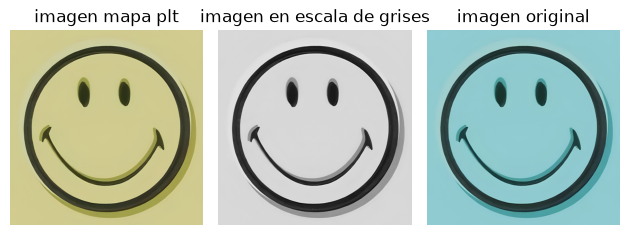

In [28]:
imgGray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
imgColor = cv.cvtColor(img, cv.COLOR_BGR2RGB)

images = [img, imgGray, imgColor]
titles = ["imagen mapa plt", "imagen en escala de grises", "imagen original"]
gray = [False, True, False]

images_dict = {
    "images": [img, imgGray, imgColor],
    "titles": ["imagen mapa plt", "imagen en escala de grises", "imagen original"],
    "gray": [False, True, False]
}

plot_single_image(images=images_dict["images"], 
            titles=images_dict["titles"], 
            isgray=images_dict["gray"])

Ya con los mapas de colores clave, podemos empezar a mostrar únicamente la imagen en blanco y negro, lo cuál nos ayudará a la detección de las facciones. Para ello probamos diferentes métodos de "threshold" que proporciona `opencv`. Partimos de la base de la imagen en escalas de grises.

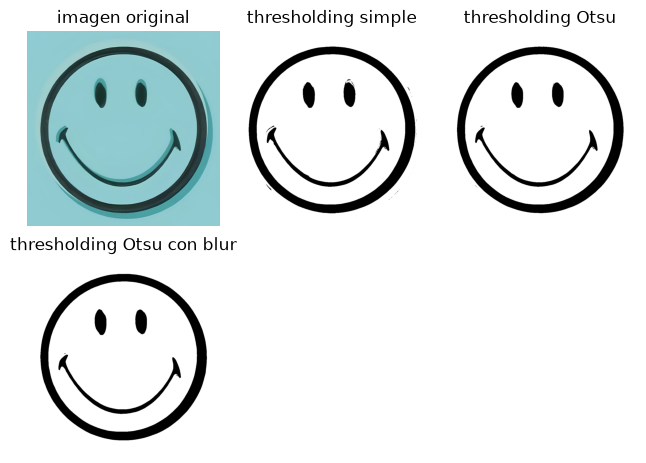

In [29]:
#simple
ret,imgSimpleTh = cv.threshold(imgGray,127,255,cv.THRESH_BINARY)

#Otsu
ret2,imgOtsuTh = cv.threshold(imgGray,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

#gaussiano + Otsu
blur = cv.GaussianBlur(imgGray,(5,5),0)
ret3,imgGaussTh = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

threshold_images = {
    "images": [imgColor, imgSimpleTh, imgOtsuTh, imgGaussTh],
    "titles": ["imagen original", "thresholding simple", "thresholding Otsu", "thresholding Otsu con blur"],
    "gray": [False, True, True, True]
}

plot_single_image(images=threshold_images["images"], 
            titles=threshold_images["titles"], 
            isgray=threshold_images["gray"])

Claramente Otsu es el ganador, vamos a aplicarlo sobre todas las imágenes.

In [30]:
for image in os.listdir(face_dir):
    img_path = os.path.join(face_dir, image)
    ret, img = process_Otsu_image(image=image, img_path=img_path)
    cv.imwrite(os.path.join(gray_processed, image), img)

print("Archivos guardados correctamente")

Archivos guardados correctamente


Vamos a ver el resultado de algunos

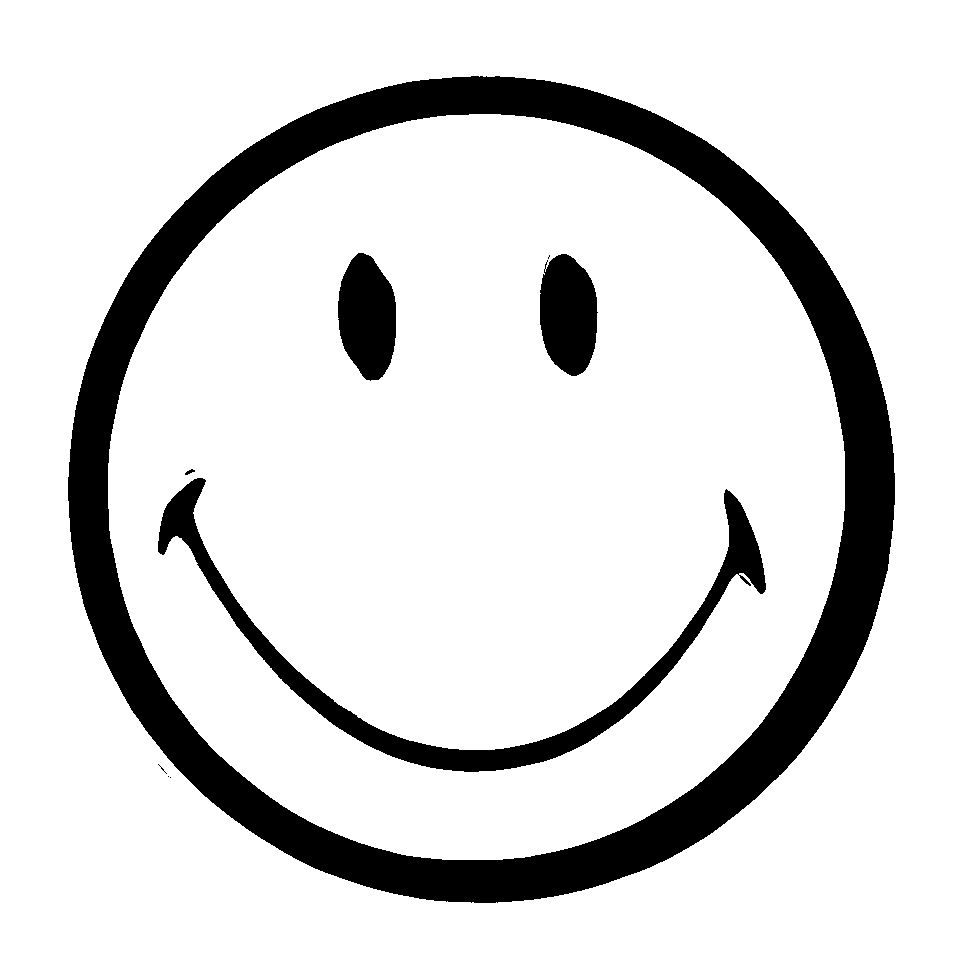

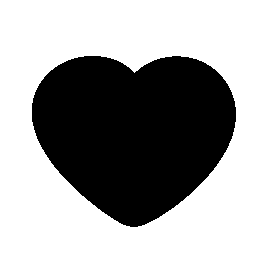

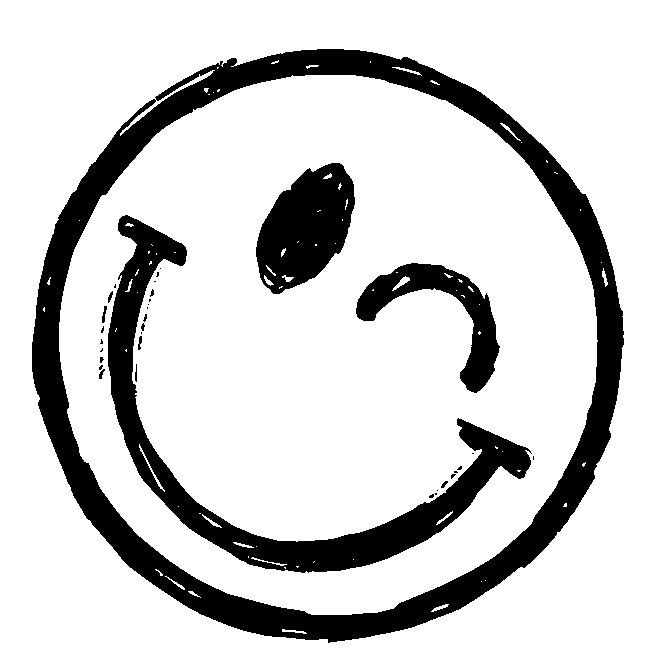

In [31]:
images2display = ["blue", "f10_spo_heart", "f12_sws_wink"]

for image in images2display:
    display(Image(filename=f"{gray_processed}/{image}.png", width=200, height=200))

Solo se han mostrado 3 imágenes de ejemplo, la primera y la tercera están correctamente coloreadas en blanco y negro, sin embargo, la segunda (el corazón) no. Esto es debido a que los umbrales de Otsu no han sido lo suficientemente precisos para clasificar el color del relleno como no relevante. 
Vamos a probar otra técnica, pasaremos las imágenes a HSV y nos quedaremos con la tercera capa que indica el brillo de la imagen. Por tanto, al aplicarlo sobre la imagen, nos quedará en blanco y negro limpios.

Archivos guardados correctamente


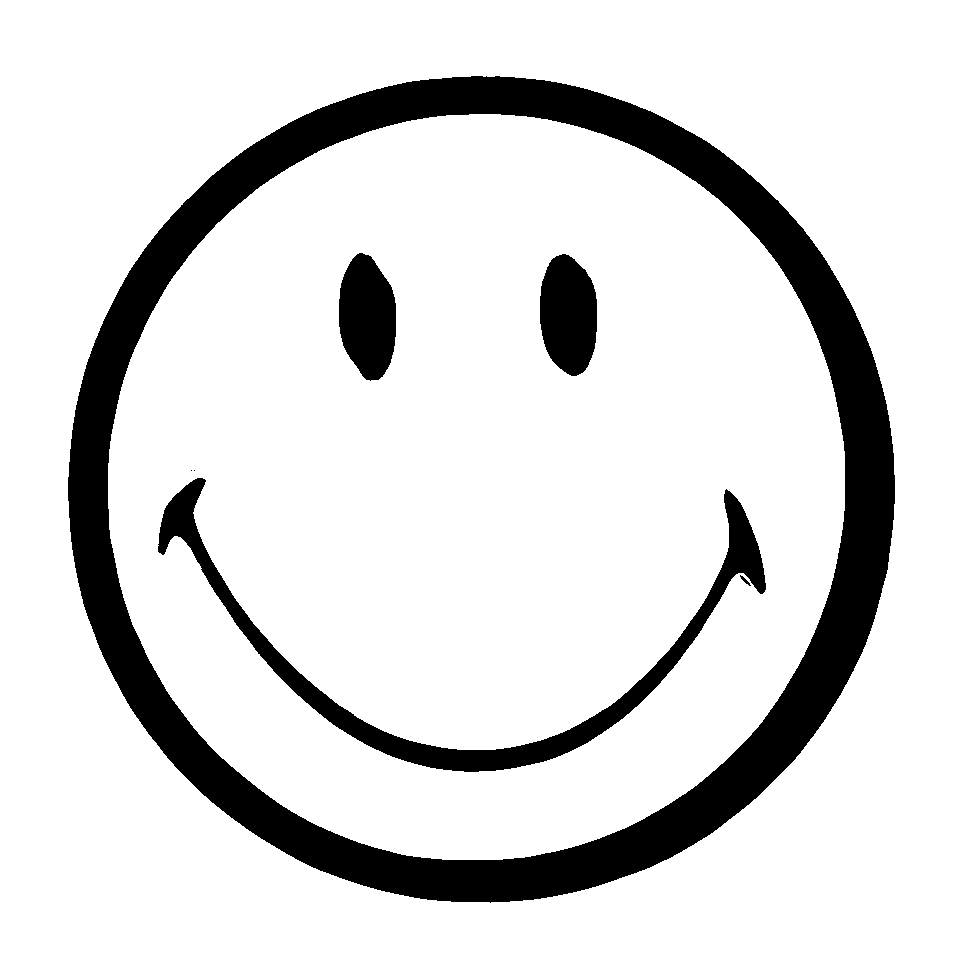

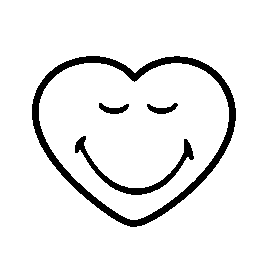

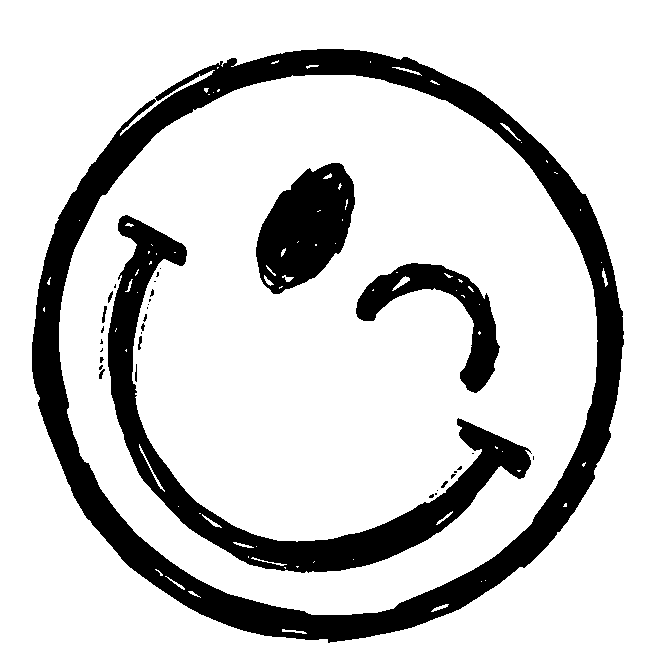

In [32]:
for image in os.listdir(face_dir):
    img_path = os.path.join(face_dir, image)
    ret, img = process_HSV_image(image=image, img_path=img_path)
    cv.imwrite(os.path.join(hsv_processed, image), img)

print("Archivos guardados correctamente")

images2display = ["blue", "f10_spo_heart", "f12_sws_wink"]

for image in images2display:
    display(Image(filename=f"{hsv_processed}/{image}.png", width=200, height=200))

Ya estaría solucionado.

## Reconocimiento de ojos